# Basic plots [^download]

[^download]: This notebook can be downloaded as **{nb-download}
repr(example_HF.ipynb) **.

This notebook shows you how to plot basic barplots and inter-annotator agreement.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from pandas import Timedelta

from disclose.dataclass.detection_data import DetectionData

### Load data

In [2]:
config = {
    "detection_file": Path(r"_static/APOCADO_results.csv"),
    "timebin_new": Timedelta("60s"),
    "filename_format": "%Y-%m-%dT%H-%M-%S",
}

data = DetectionData.from_dict(config)

### Overview

In [3]:
data.overview(annotator=data.annotator)

annotator,annotator1,annotator2
label,,
Buzz,270,208
Click,458,280
Whistle,411,466


### Single barplot

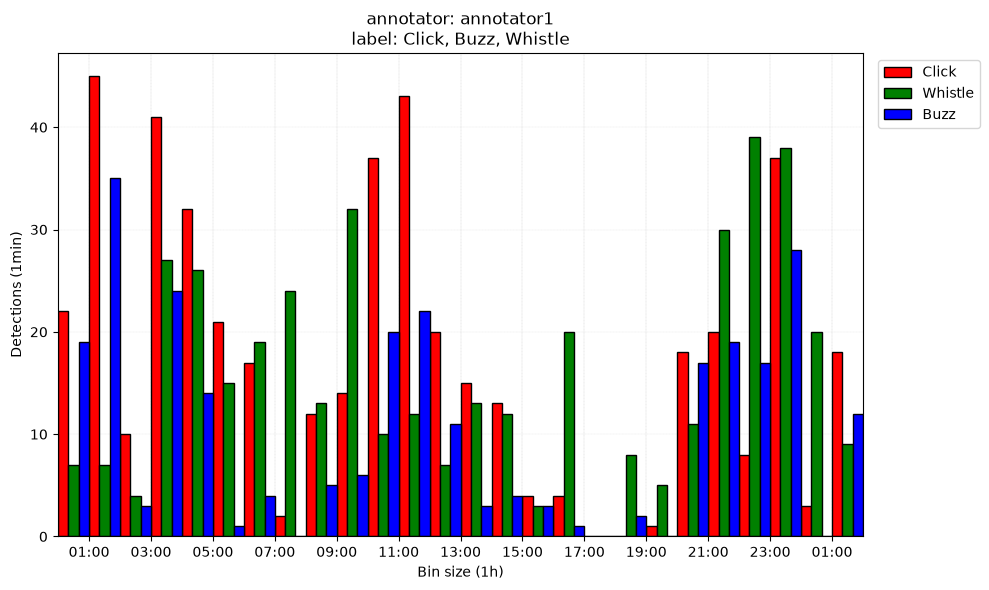

In [17]:
fig, ax = plt.subplots(figsize=(10, 6))

data.plot.histogram(
    ax=ax,
    annotator="annotator1",
    label=["Buzz", "Click", "Whistle"],
    bin_size=Timedelta("1h"),
    legend=True,
    color=["red", "green", "blue"],
)
data.plot.set_ax(
    ax=ax,
    x_ticks_res=Timedelta("2h"),
    date_format="%H:%M",
)
plt.show()

### Multi-barplot

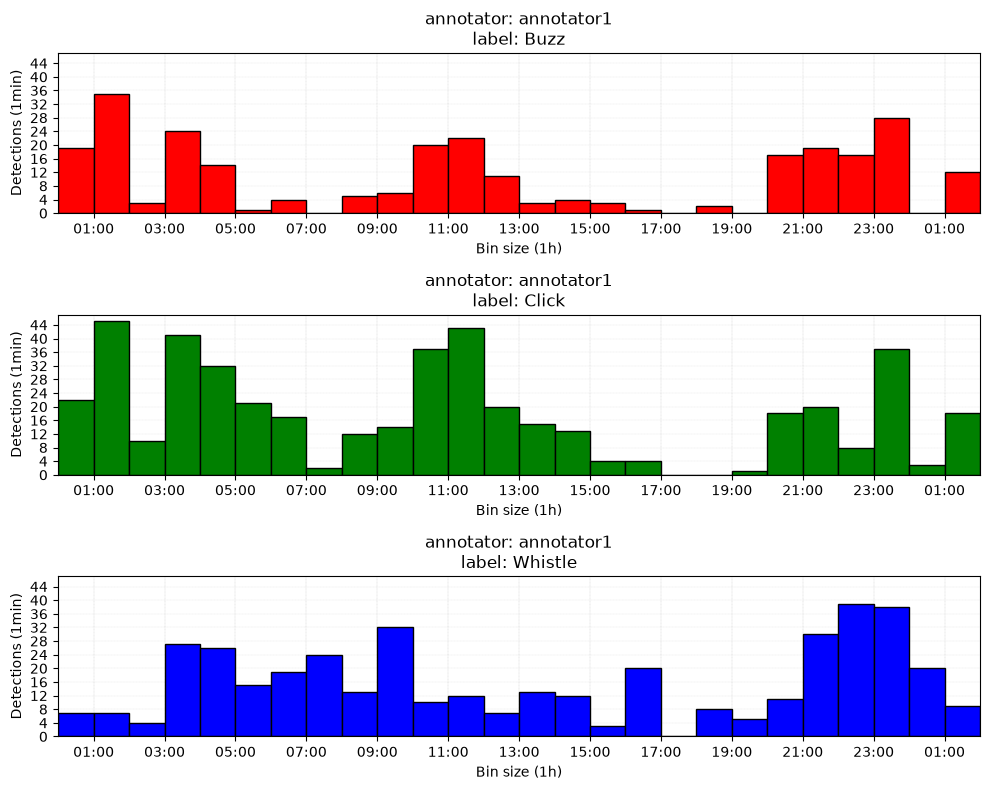

In [16]:
fig, axs = plt.subplots(3, 1, figsize=(10, 8))

lim = []
color = ["red", "green", "blue"]
for i, ax in enumerate(axs):
    data.plot.histogram(
        ax=ax,
        annotator="annotator1",
        label=data.label[i],
        bin_size=Timedelta("1h"),
        color=color[i],
    )
    data.plot.set_ax(
        ax=ax,
        x_ticks_res=Timedelta("2h"),
        date_format="%H:%M",
    )
    lim.append(axs[i].get_ylim()[-1])

for ax in axs:
    ax.set_ylim([0, int(max(lim))])
    ax.set_yticks(range(0, int(max(lim)), 4))

plt.show()

### Detection performances

In [18]:
annotators = ["annotator1", "annotator2"]
labels = 2 * ["Whistle"]

score, confusion_matrix, classification = data.detection_perf(
    annotator=annotators,
    label=labels,
)

print(f"{'':#^60}")
print(f"{f'({annotators[0]}-{labels[0]}) | ({annotators[1]}-{labels[1]})':#^60}")
print(f"{'':#^60}\n")

print(f"{' Performance metrics ':#^60}")
print(
    f"{'Recall:':<30}{score.recall:>30.2f}\n"
    f"{'Precision:':<30}{score.precision:>30.2f}\n"
    f"{'F-Score:':<30}{score.f_score:>30.2f}"
)

print(f"{' Confusion matrix ':#^60}")
print(
    f"{'True positive:':<30}{confusion_matrix['true_positive']:>30}\n"
    f"{'False positive:':<30}{confusion_matrix['false_positive']:>30}\n"
    f"{'True negative:':<30}{confusion_matrix['true_negative']:>30}\n"
    f"{'False negative:':<30}{confusion_matrix['false_negative']:>30}\n"
)

############################################################
########(annotator1-Whistle) | (annotator2-Whistle)#########
############################################################

################### Performance metrics ####################
Recall:                                                 0.96
Precision:                                              0.85
F-Score:                                                0.90
##################### Confusion matrix #####################
True positive:                                           394
False positive:                                           72
True negative:                                          1079
False negative:                                           17



### Agreement

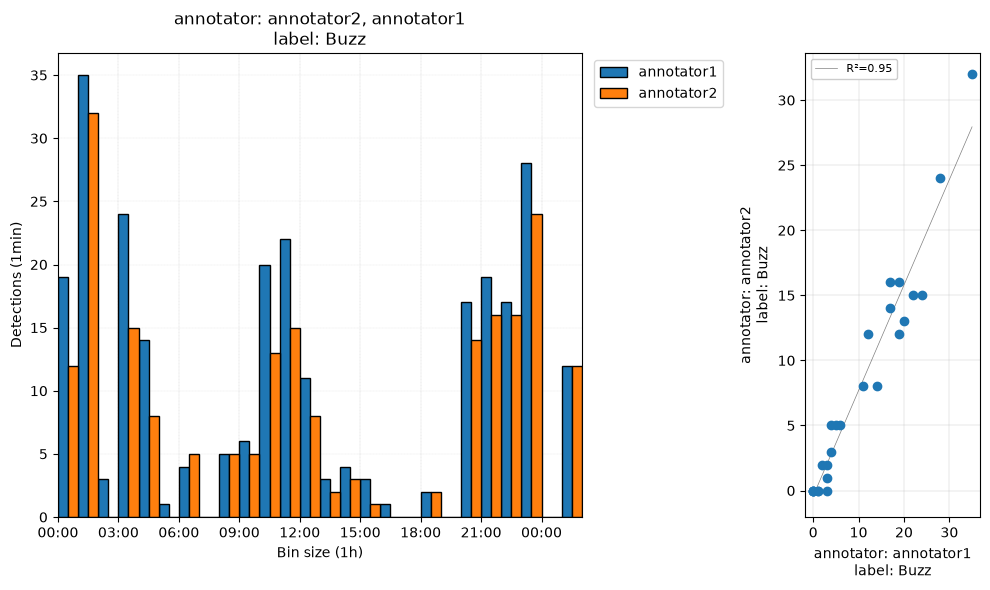

In [26]:
fig, (ax1, ax2) = plt.subplots(
    1, 2, gridspec_kw={"width_ratios": [3, 1]}, figsize=(10, 6)
)

annotators = ["annotator1", "annotator2"]
label = "Buzz"

data.plot.histogram(
    ax=ax1,
    annotator=annotators,
    label=label,
    bin_size=Timedelta("1h"),
    legend=True,
)

data.plot.agreement(
    ax=ax2,
    annotator=annotators,
    label=label,
    bin_size=Timedelta("1h"),
)

data.plot.set_ax(
    ax=ax1,
    x_ticks_res=Timedelta("3h"),
    date_format="%H:%M",
)

plt.show()